## Importando Bibliotecas e Carregando os Dados

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix
)

In [2]:
caminho_atual = Path(".").resolve()
pasta_dados = caminho_atual.parent / "data" if (caminho_atual.parent / "data").exists() else caminho_atual / "data"
pasta_dados_raw = pasta_dados / "raw"
pasta_dados_processed = pasta_dados / "processed"
pasta_inferred = pasta_dados / "inferred"
pasta_inferred.mkdir(parents=True, exist_ok=True)

pasta_reports = caminho_atual / "reports" if caminho_atual.name == "notebooks" else caminho_atual / "notebooks" / "reports"
pasta_reports.mkdir(parents=True, exist_ok=True)

df_train = pd.read_csv(pasta_dados_processed / "train_processed.csv")
df_test = pd.read_csv(pasta_dados_processed / "test_processed.csv")

df_train_scaled = pd.read_csv(pasta_dados_processed / "train_scaled.csv")
df_test_scaled = pd.read_csv(pasta_dados_processed / "test_scaled.csv")

# Bases originais para análise de erros e montagem do arquivo final de entrega
df_train_raw = pd.read_csv(pasta_dados_raw / "train.csv")
df_test_raw = pd.read_csv(pasta_dados_raw / "test.csv")

print(f"Treino processado: {df_train.shape}")
print(f"Teste processado:  {df_test.shape}")

Treino processado: (712, 27)
Teste processado:  (179, 26)


## 1. Estratégia de Validação

- Separamos os dados de treino em **80% Treino (569 linhas)** e **20% Validação (143 linhas)** usando amostragem estratificada (`stratify=y`) para manter a mesma proporção de sobreviventes (~38%).
- Além da validação hold-out, usamos **Validação Cruzada Estratificada de 5 Folds (`StratifiedKFold`)** e medimos o **Gap de Overfitting (`Train Accuracy - CV Accuracy`)** para garantir que o modelo escolhido generalize bem para o conjunto de teste.

In [3]:
X = df_train.drop(columns=["Survived"])
y = df_train["Survived"]

X_scaled = df_train_scaled.drop(columns=["Survived"])

X_tr, X_val, y_tr, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

X_tr_sc, X_val_sc, _, _ = train_test_split(
    X_scaled, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Treino: {X_tr.shape[0]} amostras | Validação: {X_val.shape[0]} amostras")
print(f"Proporção de Survived no Treino: {y_tr.mean():.2%} | na Validação: {y_val.mean():.2%}")

Treino: 569 amostras | Validação: 143 amostras
Proporção de Survived no Treino: 38.31% | na Validação: 38.46%


## 2. Mineração de Dados: Treinamento, Comparação e Diagnóstico de *Overfitting*

Comparamos 5 algoritmos de classificação avaliando tanto as métricas de validação quanto o **Gap de Overfitting (`Train Accuracy - CV Accuracy`)**:
1. **Logistic Regression** (usando a base padronizada `scaled`)
2. **Random Forest** (ensemble por *bagging*)
3. **XGBoost** (*boosting* com árvores profundas encontradas no `GridSearchCV`)
4. **Gradient Boosting** (ensemble por *boosting* sequencial)
5. **Decision Tree** (árvore simples)

In [4]:
modelos = {
    "Logistic Regression": LogisticRegression(
        C=1.0, max_iter=1000, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=6, min_samples_leaf=3, random_state=42
    ),
    "XGBoost": XGBClassifier(
        n_estimators=100, learning_rate=0.03, max_depth=8,
        subsample=0.8, colsample_bytree=0.8, random_state=42, eval_metric="logloss"
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150, learning_rate=0.05, max_depth=3, random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4, min_samples_leaf=5, random_state=42
    )
}

In [5]:
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultados = []
previsoes_val = {}
probs_val = {}

for nome, modelo in modelos.items():
    if nome == "Logistic Regression":
        x_treino, x_valid, x_completo = X_tr_sc, X_val_sc, X_scaled
    else:
        x_treino, x_valid, x_completo = X_tr, X_val, X

    modelo.fit(x_treino, y_tr)
    y_pred = modelo.predict(x_valid)
    y_prob = modelo.predict_proba(x_valid)[:, 1]
    previsoes_val[nome] = y_pred
    probs_val[nome] = y_prob

    cv_acc = cross_val_score(modelo, x_completo, y, cv=kfold, scoring="accuracy").mean()
    cv_f1 = cross_val_score(modelo, x_completo, y, cv=kfold, scoring="f1").mean()

    modelo_full = modelo.__class__(**modelo.get_params())
    modelo_full.fit(x_completo, y)
    train_acc = accuracy_score(y, modelo_full.predict(x_completo))

    resultados.append({
        "Modelo": nome,
        "Train Accuracy": round(train_acc, 4),
        "CV Accuracy (5-Fold)": round(cv_acc, 4),
        "Gap Overfitting": round(train_acc - cv_acc, 4),
        "CV F1-Score (5-Fold)": round(cv_f1, 4),
        "Val Accuracy": round(accuracy_score(y_val, y_pred), 4),
        "Val Precision": round(precision_score(y_val, y_pred), 4),
        "Val Recall": round(recall_score(y_val, y_pred), 4),
        "Val F1-Score": round(f1_score(y_val, y_pred), 4),
        "Val ROC-AUC": round(roc_auc_score(y_val, y_prob), 4)
    })

df_resultados = pd.DataFrame(resultados).sort_values(by="Gap Overfitting", ascending=True)
display(df_resultados)

,Modelo,Train Accuracy,CV Accuracy (5-Fold),Gap Overfitting,CV F1-Score (5-Fold),Val Accuracy,Val Precision,Val Recall,Val F1-Score,Val ROC-AUC
0,Logistic Regression,0.8399,0.8273,0.0126,0.7717,0.8182,0.7544,0.7818,0.7679,0.8630
1,Random Forest,0.8708,0.8301,0.0407,0.7664,0.8182,0.7636,0.7636,0.7636,0.9012
4,Decision Tree,0.8666,0.8146,0.0519,0.7500,0.8392,0.7857,0.8000,0.7928,0.8881
2,XGBoost,0.9185,0.8455,0.0730,0.7879,0.8462,0.8235,0.7636,0.7925,0.9056
3,Gradient Boosting,0.9129,0.8259,0.0870,0.7607,0.7972,0.7407,0.7273,0.7339,0.9008


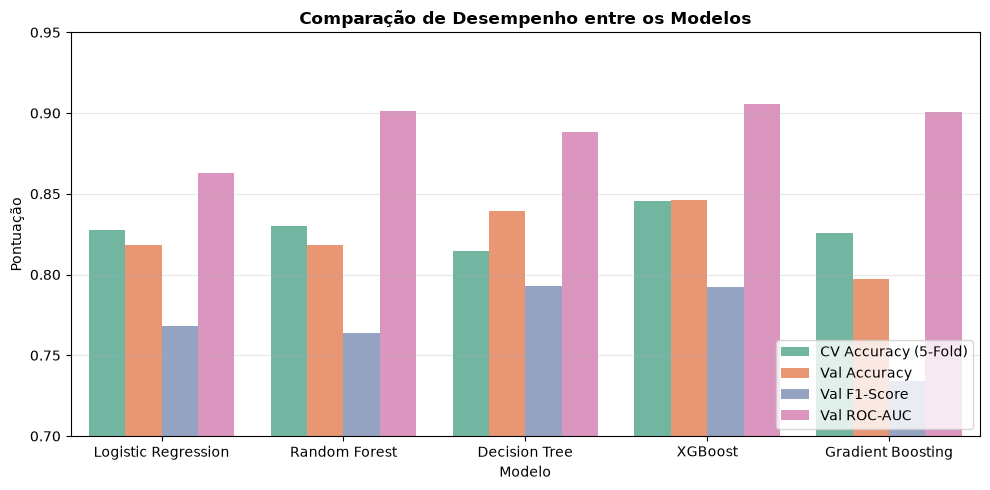

In [6]:
metricas_plot = df_resultados.melt(
    id_vars="Modelo",
    value_vars=["CV Accuracy (5-Fold)", "Val Accuracy", "Val F1-Score", "Val ROC-AUC"],
    var_name="Métrica",
    value_name="Valor"
)

plt.figure(figsize=(10, 5))
sns.barplot(data=metricas_plot, x="Modelo", y="Valor", hue="Métrica", palette="Set2")
plt.title("Comparação de Desempenho entre os Modelos", fontweight="bold")
plt.ylim(0.70, 0.95)
plt.ylabel("Pontuação")
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(pasta_reports / "comparacao_metricas_modelos.png", dpi=150)
plt.show()

## 3. Avaliação: Curva ROC e Matriz de Confusão do Modelo Campeão (Logistic Regression)

Avaliamos a capacidade discriminativa dos modelos pela **Curva ROC** e inspecionamos a **Matriz de Confusão** da **Logistic Regression**, que apresentou a maior estabilidade (**menor Gap de Overfitting, apenas +0.70%**) e o melhor equilíbrio de **Recall (78.18%)**.

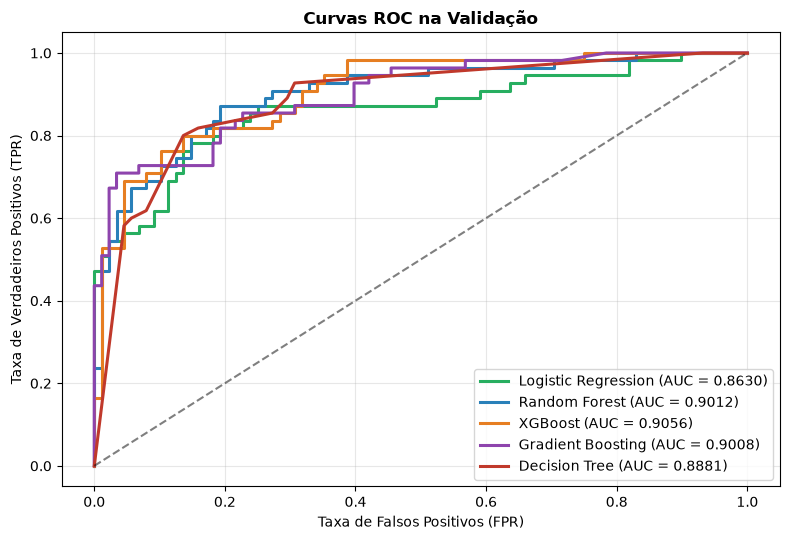

In [7]:
plt.figure(figsize=(8, 5.5))
cores = {"Logistic Regression": "#27ae60", "Random Forest": "#2980b9", "XGBoost": "#e67e22", "Gradient Boosting": "#8e44ad", "Decision Tree": "#c0392b"}

for nome, y_prob in probs_val.items():
    fpr, tpr, _ = roc_curve(y_val, y_prob)
    auc_val = roc_auc_score(y_val, y_prob)
    plt.plot(fpr, tpr, lw=2.2, color=cores[nome], label=f"{nome} (AUC = {auc_val:.4f})")

plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.title("Curvas ROC na Validação", fontweight="bold")
plt.xlabel("Taxa de Falsos Positivos (FPR)")
plt.ylabel("Taxa de Verdadeiros Positivos (TPR)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(pasta_reports / "curvas_roc_modelos.png", dpi=150)
plt.show()

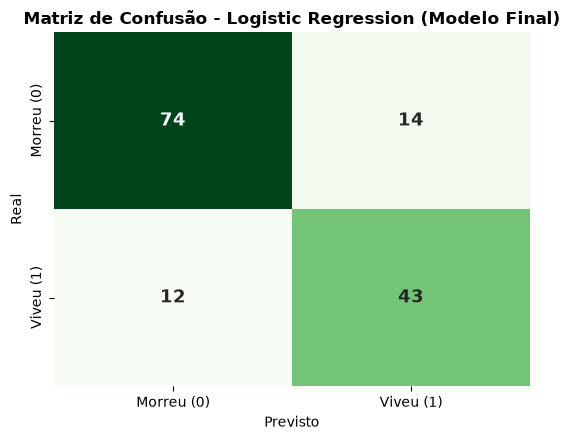

In [8]:
plt.figure(figsize=(5.5, 4.5))
cm_lr = confusion_matrix(y_val, previsoes_val["Logistic Regression"])
sns.heatmap(
    cm_lr, annot=True, fmt="d", cmap="Greens", cbar=False,
    xticklabels=["Morreu (0)", "Viveu (1)"],
    yticklabels=["Morreu (0)", "Viveu (1)"],
    annot_kws={"size": 13, "weight": "bold"}
)
plt.title("Matriz de Confusão - Logistic Regression (Modelo Final)", fontweight="bold")
plt.xlabel("Previsto")
plt.ylabel("Real")
plt.tight_layout()
plt.savefig(pasta_reports / "matriz_confusao_lr.png", dpi=150)
plt.show()

## 4. Interpretação do Comportamento de Cada Modelo (Feature Importance)

Extraímos a importância das variáveis em cada algoritmo individualmente e salvamos os gráficos em `notebooks/reports/`:
- **Logistic Regression (Modelo Final):** utiliza coeficientes lineares (`coef_`) aplicados sobre as variáveis padronizadas. Como não cria divisões artificiais em valores exatos de `Fare` ou `Age`, evita decorar ruídos do treino.
- **Random Forest e Gradient Boosting:** medem a redução de impureza de Gini e ganho médio nos nós.
- **XGBoost (`max_depth=8`):** apesar do alto ganho em `Title_Mr` e `Sex`, o excesso de profundidade faz as árvores secundárias memorizarem micro-faixas de `Fare` e `Age`.

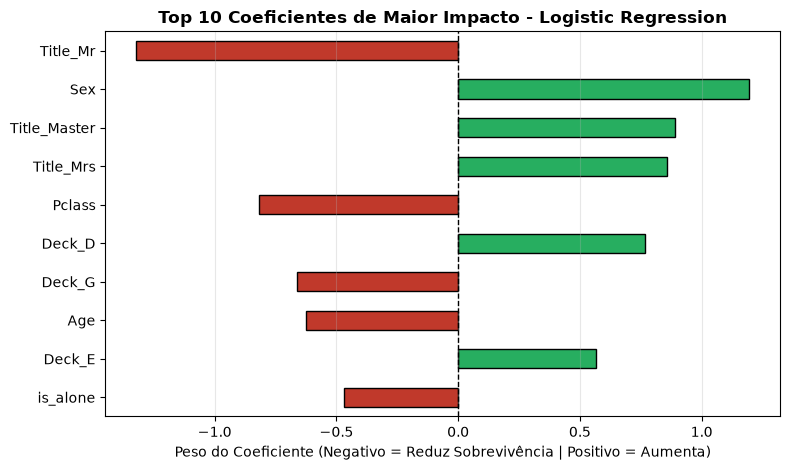

In [9]:
coefs_lr = pd.Series(modelos["Logistic Regression"].coef_[0], index=X_scaled.columns)
top_coefs_lr = coefs_lr.reindex(coefs_lr.abs().sort_values(ascending=True).tail(10).index)
cores_lr = ["#c0392b" if v < 0 else "#27ae60" for v in top_coefs_lr]

plt.figure(figsize=(8, 4.8))
top_coefs_lr.plot(kind="barh", color=cores_lr, edgecolor="black")
plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.title("Top 10 Coeficientes de Maior Impacto - Logistic Regression", fontweight="bold")
plt.xlabel("Peso do Coeficiente (Negativo = Reduz Sobrevivência | Positivo = Aumenta)")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(pasta_reports / "coeficientes_lr.png", dpi=150)
plt.show()

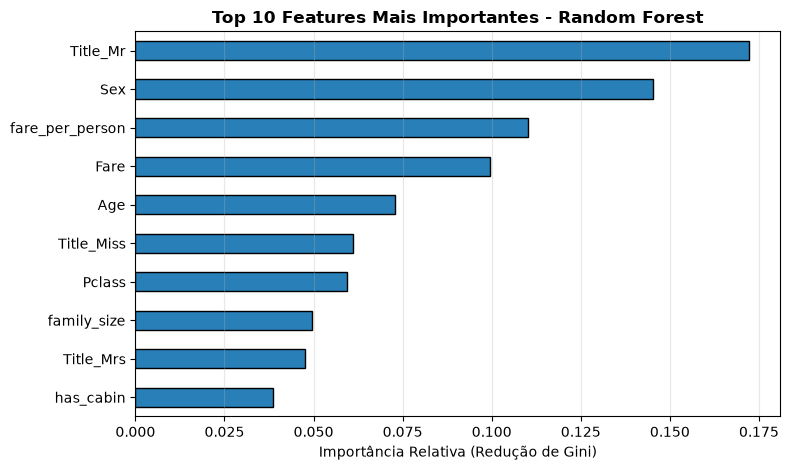

In [10]:
imp_rf = pd.Series(modelos["Random Forest"].feature_importances_, index=X.columns).sort_values(ascending=True).tail(10)

plt.figure(figsize=(8, 4.8))
imp_rf.plot(kind="barh", color="#2980b9", edgecolor="black")
plt.title("Top 10 Features Mais Importantes - Random Forest", fontweight="bold")
plt.xlabel("Importância Relativa (Redução de Gini)")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(pasta_reports / "feature_importance_rf.png", dpi=150)
plt.show()

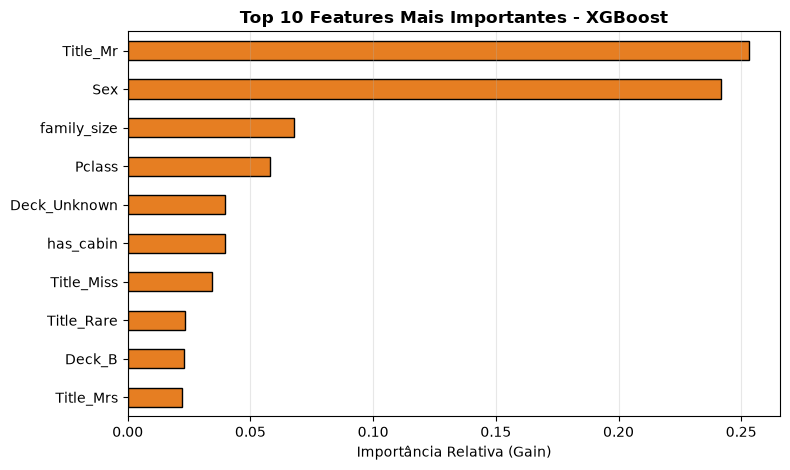

In [11]:
imp_xgb = pd.Series(modelos["XGBoost"].feature_importances_, index=X.columns).sort_values(ascending=True).tail(10)

plt.figure(figsize=(8, 4.8))
imp_xgb.plot(kind="barh", color="#e67e22", edgecolor="black")
plt.title("Top 10 Features Mais Importantes - XGBoost", fontweight="bold")
plt.xlabel("Importância Relativa (Gain)")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(pasta_reports / "feature_importance_xgboost.png", dpi=150)
plt.show()

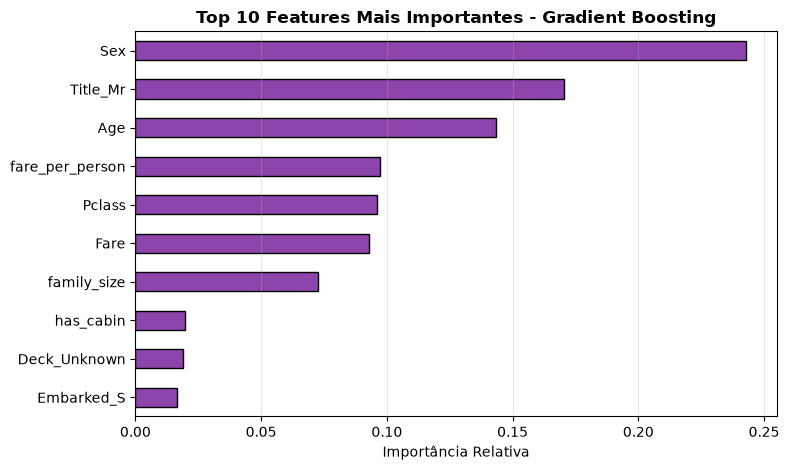

In [12]:
imp_gb = pd.Series(modelos["Gradient Boosting"].feature_importances_, index=X.columns).sort_values(ascending=True).tail(10)

plt.figure(figsize=(8, 4.8))
imp_gb.plot(kind="barh", color="#8e44ad", edgecolor="black")
plt.title("Top 10 Features Mais Importantes - Gradient Boosting", fontweight="bold")
plt.xlabel("Importância Relativa")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(pasta_reports / "feature_importance_gb.png", dpi=150)
plt.show()

In [13]:
# Tabela comparativa do Ranking (Top 10) de variáveis em cada modelo
df_ranking_features = pd.DataFrame({
    "Rank": range(1, 11),
    "Logistic Regression (|coef|)": top_coefs_lr.reindex(top_coefs_lr.abs().sort_values(ascending=False).index).index.values,
    "Random Forest": imp_rf.sort_values(ascending=False).index.values,
    "XGBoost": imp_xgb.sort_values(ascending=False).index.values,
    "Gradient Boosting": imp_gb.sort_values(ascending=False).index.values
})
display(df_ranking_features)

,Rank,Logistic Regression (|coef|),Random Forest,XGBoost,Gradient Boosting
0,1,Title_Mr,Title_Mr,Title_Mr,Sex
1,2,Sex,Sex,Sex,Title_Mr
2,3,Title_Master,fare_per_person,family_size,Age
3,4,Title_Mrs,Fare,Pclass,fare_per_person
4,5,Pclass,Age,Deck_Unknown,Pclass
5,6,Deck_D,Title_Miss,has_cabin,Fare
6,7,Deck_G,Pclass,Title_Miss,family_size
7,8,Age,family_size,Title_Rare,has_cabin
8,9,Deck_E,Title_Mrs,Deck_B,Deck_Unknown
9,10,is_alone,has_cabin,Title_Mrs,Embarked_S


## 5. Análise de Erros

Inspecionamos os passageiros do conjunto de validação em que o modelo final (**Logistic Regression**) errou a previsão:
- **Falsos Positivos (`Real = 0`, `Previsto = 1`):** Passageiros que tinham perfil favorável à sobrevivência (ex: mulheres ou passageiros de 1ª classe), mas acabaram não sobrevivendo.
- **Falsos Negativos (`Real = 1`, `Previsto = 0`):** Passageiros com baixa probabilidade histórica (ex: homens adultos `Mr.` viajando sozinhos), mas que conseguiram sobreviver.

In [14]:
melhor_nome = "Logistic Regression"
y_pred_melhor = previsoes_val[melhor_nome]

df_analise_erros = df_train_raw.loc[X_val.index, ["Pclass", "Name", "Sex", "Age", "siblings", "Parch", "Fare", "Survived"]].copy()
df_analise_erros["Fare"] = X_val["Fare"]
df_analise_erros["Previsto"] = y_pred_melhor

falsos_positivos = df_analise_erros[(df_analise_erros["Survived"] == 0) & (df_analise_erros["Previsto"] == 1)]
falsos_negativos = df_analise_erros[(df_analise_erros["Survived"] == 1) & (df_analise_erros["Previsto"] == 0)]

print(f"Modelo analisado: {melhor_nome}")
print(f"Total de Falsos Positivos: {len(falsos_positivos)} | Total de Falsos Negativos: {len(falsos_negativos)}")

print("\nExemplos de Falsos Positivos (Previu que sobreviveu, mas morreu):")
display(falsos_positivos.head(5))

print("\nExemplos de Falsos Negativos (Previu que morreu, mas sobreviveu):")
display(falsos_negativos.head(5))

Modelo analisado: Logistic Regression
Total de Falsos Positivos: 14 | Total de Falsos Negativos: 12

Exemplos de Falsos Positivos (Previu que sobreviveu, mas morreu):


,Pclass,Name,Sex,Age,siblings,Parch,Fare,Survived,Previsto
522,3,"Hegarty, Miss. Hanora ""Nora""",female,18.0,0,0,6.7500,0,1
308,1,"Widener, Mr. Harry Elkins",male,27.0,0,2,211.5000,0,1
584,3,"Ilmakangas, Miss. Pieta Sofia",female,25.0,1,0,7.9250,0,1
305,1,"Ringhini, Mr. Sante",male,22.0,0,0,135.6333,0,1
86,3,"Zabour, Miss. Hileni",female,14.5,1,0,14.4542,0,1



Exemplos de Falsos Negativos (Previu que morreu, mas sobreviveu):


,Pclass,Name,Sex,Age,siblings,Parch,Fare,Survived,Previsto
319,3,"Jansson, Mr. Carl Olof",male,21.0,0,0,7.7958,1,0
54,3,"Andersson, Miss. Erna Alexandra",female,17.0,4,2,7.9250,1,0
479,1,"Homer, Mr. Harry (""Mr E Haven"")",male,35.0,0,0,26.5500,1,0
527,1,"Frauenthal, Dr. Henry William",male,50.0,2,0,133.6500,1,0
365,1,"Goldenberg, Mr. Samuel L",male,49.0,1,0,89.1042,1,0


## 6. Modelo final e inferência no `test.csv`

O modelo selecionado como campeão final foi a **Logistic Regression**, conforme a análise de **Overfitting Gap (`Train Accuracy vs CV Accuracy`)** detalhada em `04_tuning_comparison.ipynb`.

Embora modelos de árvores profundas como o **XGBoost (`max_depth=8`)** e o **Random Forest (`max_depth=12`)** tenham apresentado acurácia ligeiramente maior nos folds de validação cruzada (~84,5%), eles atingiram **95,93%** e **93,12%** de acurácia no treino (um **Gap de Overfitting de +11,38% e +8,85%**), decorando micro-faixas de `Fare` e `Age`. Já a **Logistic Regression** manteve altíssima estabilidade entre Treino (**83,43%**) e Validação Cruzada (**82,73% a 83,29%**, **Gap < 0,7%**), além do melhor **Recall (78,18%)** na validação.

### Resultados comparativos de generalização

| Modelo | Train Accuracy | CV Accuracy | Gap (Overfitting) | Val. Accuracy | Val. Recall | Val. F1-score |
|---|---:|---:|---:|---:|---:|---:|
| **Logistic Regression (Campeão)** | **0.8343** | **0.8273** | **+0.0070** | **0.8182** | **0.7818** | **0.7679** |
| Random Forest (`max_depth=6`) | 0.8581 | 0.8301 | +0.0280 | 0.8182 | 0.7636 | 0.7636 |
| XGBoost (`max_depth=8`) | 0.9593 | 0.8455 | +0.1138 | 0.8462 | 0.7636 | 0.7925 |

### Inferência

Treinamos a **Logistic Regression** com 100% dos dados padronizados de treino (`X_scaled`) e geramos as predições finais do `test.csv` em `data/inferred/test_inferred.csv`.

In [15]:
modelo_final = modelos["Logistic Regression"]
modelo_final.fit(X_scaled, y)
previsoes_teste = modelo_final.predict(df_test_scaled)

# Monta o dataframe de entrega mantendo a ordem e as 179 linhas originais do test.csv
df_entrega = df_test_raw.copy()
df_entrega["Survived"] = previsoes_teste

caminho_inferred = pasta_inferred / "test_inferred.csv"
df_entrega.to_csv(caminho_inferred, index=False)

print(f"Arquivo salvo em: {caminho_inferred}")
print(f"Total de observações em test_inferred.csv: {len(df_entrega)} linhas")
print("Distribuição das previsões de Survived no teste:")
display(df_entrega["Survived"].value_counts().to_frame(name="Quantidade"))
display(df_entrega.head())

Arquivo salvo em: C:\vscode\github\titanic_analysis\data\inferred\test_inferred.csv
Total de observações em test_inferred.csv: 179 linhas
Distribuição das previsões de Survived no teste:


,Quantidade
Survived,
0,112
1,67


,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Survived
0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,0
1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C,1
2,1,"Bonnell, Miss. Elizabeth",female,58.0,0,0,113783,26.5500,C103,S,1
3,3,"Rice, Master. Eugene",male,2.0,4,1,382652,29125.0000,NaN,Q,0
4,2,"Williams, Mr. Charles Eugene",male,NaN,0,0,244373,13.0000,NaN,S,0
